# CS2 (국내반) --- Lecture 12: Graph Shooter (NumPy, Matplotlib)
### Problem Set (in-class)

*이 노트북은 채점되지 않습니다. 수업 시간에 바로 이어서 풀면 됩니다.*

- 함수 그래프를 쏴서 장애물(회색 원)을 피해 과녁(빨간 원)을 맞히는 게임
- 발사대(검은 네모)는 항상 원점 (0, 0). 총알은 y = f(x)의 그래프를 따라 x = 0부터 과녁까지 날아감. 장애물에 닿으면 **BLOCKED**, 화면 밖(|y| > 10)이면 **OUT**, 과녁에 닿으면 **HIT**, 과녁 위치까지 가도 안 닿으면 **MISS**
- 위에서부터 **순서대로** 실행: 앞에서 만든 함수(무기, 충돌 판정, 엔진)를 뒤 문제에서 그대로 씀
- 빈칸 `___`을 채우거나 함수 몸통을 직접 작성 (4번은 실행만). 1~6번 필수, 7번 Optional

### Setup

아래 **게임 준비** 셀을 **먼저 한 번 실행**하세요. 게임의 레벨, 랜덤 맵, 그리기 함수가 준비됩니다. (무기와 엔진은 아래 문제에서 다룹니다.)

In [ ]:
#@title 게임 준비 (먼저 한 번 실행)
# L13_game.py : levels, random maps and drawing for Graph Shooter.
# The cannon is always at the origin (0, 0); the screen is 0 <= x <= 20, -10 <= y <= 10.
import numpy as np
import matplotlib.pyplot as plt

np.seterr(all="ignore")       # no warnings for huge values such as np.exp(100)

# walls:  obstacles (cx, cy, r)
# target: (tx, ty, r)
LEVELS = {
    1: dict(name="Straight Shot", walls=[], target=(18, 6, 0.7)),
    2: dict(name="Over the Hill", walls=[(10, -1, 4.5)], target=(18, 0, 0.7)),
    3: dict(name="Zigzag", walls=[(6, 3, 4.7), (13, -3, 3.4)], target=(19, 2, 0.7)),
    4: dict(name="The Wall", walls=[(10, -8, 2), (10, -4, 2), (10, 0, 2), (10, 4, 1.8)], target=(16, -6, 0.7)),
    5: dict(name="Step Up", walls=[(5, 4.8, 4.2), (12.5, -0.5, 3.5)], target=(18, 7, 0.7)),
    # bonus levels for the new weapons of P06
    6: dict(name="Valley", walls=[(6, 3, 4.8), (14, 3, 4.8), (10, -9.5, 4)], target=(18, -1, 0.7)),
    7: dict(name="Elevator", walls=[(5, 4, 3.5), (15, -4, 3.5)], target=(18, 6, 0.7)),
    8: dict(name="Ramp", walls=[(6, 3.5, 3), (13, -2, 2.5)], target=(18, 8, 0.7)),
}

# a map with two ways through (used in the Bonus AI demo)
TWO_HOLES = dict(name="Two Holes", walls=[(10, -7.5, 2.0), (10, 0, 2.0), (10, 7.5, 2.0)], target=(18, 0, 0.7))

def flightPath(f, level):
    """Where the bullet really flies (for drawing): from the origin until the first wall,
    until it leaves the screen, or until it reaches the target."""
    tx, ty, tr = level["target"]
    x = np.linspace(0, tx, 2001)
    y = f(x) + 0 * x
    y = y - y[0]
    stop = np.abs(y) > 10
    for cx, cy, r in level["walls"] + [level["target"]]:
        stop = stop | (np.sqrt((x - cx) ** 2 + (y - cy) ** 2) < r)
    end = np.argmax(stop) + 1 if np.any(stop) else len(x)
    return x[:end], y[:end]

def drawLevel(level, ax=None):
    if ax is None:
        plt.figure(figsize=(8, 8))
        ax = plt.gca()
    for cx, cy, r in level["walls"]:
        ax.add_patch(plt.Circle((cx, cy), r, color="gray"))
    tx, ty, tr = level["target"]
    ax.add_patch(plt.Circle((tx, ty), tr, color="red"))
    ax.plot(0, 0, "ks", markersize=12)
    ax.set_xlim(-0.6, 20)                         # a little room for the cannon
    ax.set_ylim(-10, 10)
    ax.set_aspect("equal")
    ax.set_xticks(range(0, 21))                   # a grid line at every integer
    ax.set_yticks(range(-10, 11))
    ax.tick_params(labelsize=7)
    ax.grid(True, color="0.85")
    ax.set_axisbelow(True)                        # grid lines behind the walls
    ax.set_title(level["name"])

def integerPoints(f, level):
    """The points of the shot at x = 0, 1, 2, ... (only where the bullet really flies)."""
    xs, ys = flightPath(f, level)
    x = np.arange(0, np.floor(xs[-1]) + 1)
    y = f(x) + 0 * x
    y = y - y[0]
    return x, y

def printPoints(x, y):
    """Print the points in rows:  x=0: 0.00   x=1: 0.33   ..."""
    row = ""
    for i in range(len(x)):
        row = row + ("x=" + str(int(x[i])) + ":").rjust(5) + ("%.2f" % y[i]).rjust(7) + "   "
        if i % 6 == 5 or i == len(x) - 1:
            print(row)
            row = ""

def drawShot(f, level, result):
    """Draw one level, the shot of f, and the result: drawShot(f, level, shoot(f, level)).
    The points at integer x are marked and printed, so you can see where to change f."""
    drawLevel(level)
    xs, ys = flightPath(f, level)
    plt.plot(xs, ys, "b", linewidth=1.5)
    xi, yi = integerPoints(f, level)
    plt.plot(xi, yi, "bo", markersize=4)
    plt.title(level["name"] + ": " + result)
    printPoints(xi, yi)
    plt.show()

# ---------------- random maps ----------------
def _canHit(level):
    """True if some simple shot (line, hill or step) hits the target. Used to skip impossible maps."""
    tx, ty, tr = level["target"]
    tries = []
    for a in np.linspace(-1, 1, 81):
        tries.append(lambda x, a=a: a * x)
    for h in np.linspace(-14, 14, 57):
        tries.append(lambda x, h=h: ty * x / tx - h * x * (x - tx) / 100)
        tries.append(lambda x, h=h: h / (1 + np.exp(-1.5 * (x - 10))))
    for f in tries:
        xs, ys = flightPath(f, level)
        if np.sqrt((xs[-1] - tx) ** 2 + (ys[-1] - ty) ** 2) < tr:
            return True
    return False

def randomLevel(seed):
    """A random map that can be cleared. The same seed always gives the same map."""
    rng = np.random.default_rng(seed)
    while True:
        walls = []
        for i in range(4):
            walls.append((rng.uniform(4, 15), rng.uniform(-8, 8), rng.uniform(1, 2.5)))
        target = (rng.uniform(16, 19), rng.uniform(-7, 7), 0.7)
        level = dict(name="Seed " + str(seed), walls=walls, target=target)
        free = True
        for cx, cy, r in walls:
            if np.sqrt((target[0] - cx) ** 2 + (target[1] - cy) ** 2) < r + 1.5:
                free = False
            if np.sqrt(cx ** 2 + cy ** 2) < r + 1:
                free = False
        xs, ys = flightPath(lambda x: 0 * x, level)          # a flat shot must not win
        flatHits = np.sqrt((xs[-1] - target[0]) ** 2 + (ys[-1] - target[1]) ** 2) < target[2]
        if free and not flatHits and _canHit(level):
            return level

def drawCatalog(functions):
    """functions: a dictionary {name: function}. Draws each one."""
    x = np.linspace(-4, 4, 801)
    plt.figure(figsize=(12, 6))
    k = 0
    for name in functions:
        k = k + 1
        plt.subplot(2, 3, k)
        plt.axhline(0, color="0.7")
        plt.axvline(0, color="0.7")
        plt.plot(x, functions[name](x), linewidth=2)
        plt.xlim(-4, 4)
        plt.ylim(-3, 4)
        plt.title(name)
    plt.tight_layout()
    plt.show()

# ---------------- AI demo ----------------
def showTraining(level, network, snapshots, losses):
    """snapshots: list of (step, p). Left: every snapshot's shot on one map
    (light = early, dark = late). Right: the loss curve."""
    plt.figure(figsize=(13, 5.5))
    ax = plt.subplot(1, 2, 1)
    drawLevel(level, ax)
    colors = plt.cm.viridis_r(np.linspace(0.1, 1, len(snapshots)))
    for k in range(len(snapshots)):
        step, p = snapshots[k]
        xs, ys = flightPath(lambda x: network(p, x), level)
        ax.plot(xs, ys, color=colors[k], linewidth=2, label="step " + str(step))
    ax.legend(loc="lower right", fontsize=8)
    ax.set_title(level["name"] + ": shots while training")
    ax = plt.subplot(1, 2, 2)
    ax.plot(losses)
    for step, p in snapshots:
        ax.plot(step, losses[step], "o", color="0.4")
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_ylabel("loss")
    ax.set_title("loss: how bad the shot is")
    ax.grid(True)
    plt.tight_layout()
    plt.show()

def showResults(shots, network):
    """shots: list of (level, p, result). One small map per test."""
    n = len(shots)
    cols = 4
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(3.2 * cols, 3.2 * rows))
    for k in range(n):
        level, p, result = shots[k]
        ax = plt.subplot(rows, cols, k + 1)
        drawLevel(level, ax)
        xs, ys = flightPath(lambda x: network(p, x), level)
        ax.plot(xs, ys, "b", linewidth=2)
        ax.set_xticks(range(0, 21, 5))
        ax.set_yticks(range(-10, 11, 5))
        ax.tick_params(labelsize=7)
        ax.set_title(level["name"] + ": " + result, fontsize=10,
                     color="green" if result == "HIT" else "red")
    plt.tight_layout()
    plt.show()

### Problem 1

(Plotting Practice) 맨 위에 import 두 줄을 직접 입력하고, 함수 몸통을 직접 작성 (빈칸 없음).

그리는 순서: `plt.figure()` (빈 그림) → `plt.plot(...)` 여러 번 (겹쳐 그림) → `plt.show()`

#### 1-(1) `drawSquares`

- action: 점 (0, 0), (1, 1), (2, 4), (3, 9), (4, 16)을 좌표 list `x`, `y`로 만들고, 점과 선(`"o-"`)으로 그림. 제목 `y = x^2`

In [ ]:
# Type the two import lines: numpy as np, matplotlib.pyplot as plt

def drawSquares():
    # points (0, 0), (1, 1), (2, 4), (3, 9), (4, 16): y = x^2
    # 1. make the lists x and y
    # 2. plt.figure(), then plot them as dots joined by lines ("o-")
    # 3. title "y = x^2", show
    pass

drawSquares()

#### 1-(2) `drawSinCos`

- action: $0 \le x \le 2\pi$에서 30개의 점으로 $\sin x$와 $\cos x$를 그림. 격자와 범례 표시
- 스타일: sin은 `color="red"`, `marker="o"`, `linestyle="--"`, label `sin` / cos는 `color="orange"`, label `cos`

*$\pi$는 `np.pi`.*

In [ ]:
def drawSinCos():
    # 1. x: 30 numbers from 0 to 2 * np.pi    (np.linspace)
    # 2. plt.figure()
    # 3. sin x: color "red", marker "o", linestyle "--", label "sin"
    # 4. cos x: color "orange", label "cos"
    # 5. grid, legend, show
    pass

drawSinCos()

### Problem 2

**Weapons (from Deep Learning)** 여기서 만든 함수가 Problem 5, 6의 **무기**가 됩니다.

#### 2-(0) import

맨 위에 import 두 줄을 직접 입력: `import numpy as np`, `import matplotlib.pyplot as plt`

In [ ]:
# Type the two import lines: numpy as np, matplotlib.pyplot as plt

#### 2-(1) `relu`

- input parameter: an array `x`
- return value: 각 원소에 대해 $x$와 $0$ 중 큰 값 (`np.maximum`)

이런 모양이 나와야 함:

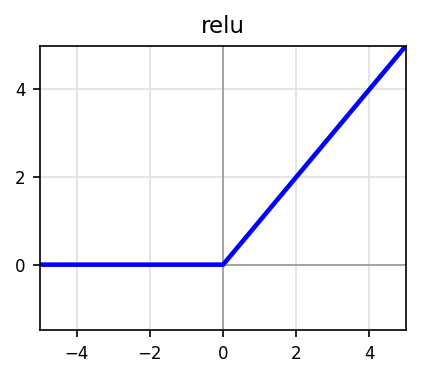

In [ ]:
p = np.array([-2, 0, 3])          # test input

def relu(x):
    return ___

print(relu(p))                  # [0 0 3]

#### 2-(2) `leakyRelu`

- input parameter: an array `x`
- return value: 각 원소에 대해 $x > 0$이면 $x$, 아니면 $0.1x$ (`np.where`)

이런 모양이 나와야 함:

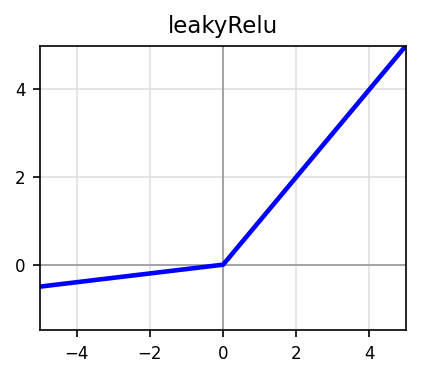

In [ ]:
def leakyRelu(x):
    return ___

print(leakyRelu(p))             # [-0.2  0.   3. ]

#### 2-(3) `sigmoid`

- input parameter: an array `x`
- return value: 각 원소에 대해 $\dfrac{1}{1 + e^{-x}}$

*$e^{x}$는 `np.exp(x)`.*

이런 모양이 나와야 함:

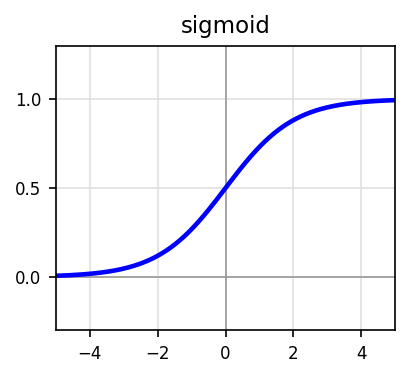

In [ ]:
def sigmoid(x):
    return ___

print(np.round(sigmoid(p), 3))  # [0.119 0.5   0.953]

#### 2-(4) `tanh`

- input parameter: an array `x`
- return value: 각 원소에 대해 $\dfrac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$ (`np.tanh`를 쓰지 말고 공식으로)

이런 모양이 나와야 함:

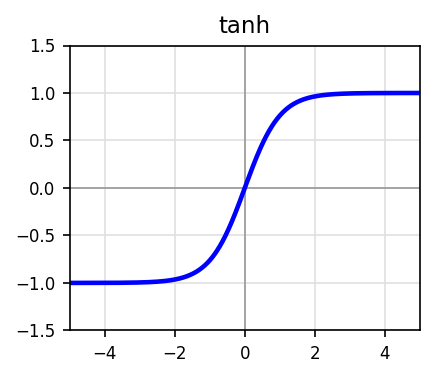

In [ ]:
def tanh(x):
    return ___

print(np.round(tanh(p), 3))     # [-0.964  0.     0.995]

#### 2-(5) `drawFunctions`

- action: $-5 \le x \le 5$에서 네 함수의 그래프를 `label`과 함께 그림. 보이는 범위는 x: $-5 \sim 5$, y: $-2 \sim 5$, 격자와 범례 표시
- 함수 몸통 전체를 직접 작성 (`np.linspace`, `plt.figure`, `plt.plot`, `plt.xlim`, `plt.ylim`, `plt.grid`, `plt.legend`, `plt.show`)

In [ ]:
def drawFunctions():
    # 1. x: 201 numbers from -5 to 5          (np.linspace)
    # 2. plt.figure(), then plot relu, leakyRelu, sigmoid, tanh
    #    (plt.plot with label=...)
    # 3. x axis -5 ~ 5, y axis -2 ~ 5, grid, legend, show
    pass

drawFunctions()

#### 2-(6) `drawMoves`

- action: $-3 \le x \le 9$에서 `relu(x)`, `2 * relu(x)`, `relu(x - 3)`, `relu(x) - relu(x - 3)`의 그래프를 `label`과 함께 그림. 격자와 범례 표시

*`a * f(x)`: 위아래로 늘이기, `f(x - c)`: 오른쪽으로 c만큼, `f(x) + g(x)`: 더하기*

In [ ]:
def drawMoves():
    # 1. x: 241 numbers from -3 to 9
    # 2. plt.figure(), then plot with labels:
    #    relu(x), 2 * relu(x), relu(x - 3), relu(x) - relu(x - 3)
    # 3. grid, legend, show
    pass

drawMoves()

### Problem 3

(Collision) 예제 코드 (빈칸 없음). 실행해서 결과 확인.
- `d`: 각 점에서 원의 중심 (3, 0)까지 거리
- `d < r`: 원 안에 있으면 True

In [ ]:
import numpy as np

x = np.array([0, 1, 2, 3])
y = np.array([0, 0, 0, 0])
cx, cy, r = 3, 0, 1.5                       # center (3, 0), radius 1.5
d = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)  # distance to the center
print(d)      # [3. 2. 1. 0.]
print(d < r)  # [False False  True  True]

### Problem 4

(The Shooting Engine) 게임 엔진은 **완성되어 있음** (빈칸 없음). 코드를 읽고 실행해서 결과 네 가지를 확인.
- `startAtOrigin(y)`: 그래프를 위아래로 옮겨서 원점 (0, 0)에서 출발
- `offScreen(y)`: |y| > 10인 값이 하나라도 있으면 True
- `touches(x, y, circle)`: 총알의 점 중 하나라도 원 안에 있으면 True (`insideCircle`: Problem 3의 거리 계산 그대로)
- `shoot(f, level)`: 화면 밖이면 `"OUT"`, 장애물에 닿으면 `"BLOCKED"`, 과녁에 닿으면 `"HIT"`, 그 외 `"MISS"`

*테스트의 `flat`, `hill`, `down`, `steep`이 각각 어떤 결과가 나오는지 그림과 함께 확인.*

In [ ]:
import numpy as np

def insideCircle(x, y, cx, cy, r):   # same distance check as P03
    return np.sqrt((x - cx) ** 2 + (y - cy) ** 2) < r

def startAtOrigin(y):            # move the graph up or down: y[0] becomes 0
    return y - y[0]

def offScreen(y):                # did it leave the screen (|y| > 10)?
    return np.any(np.abs(y) > 10)

def touches(x, y, circle):       # did the bullet touch this circle?
    cx, cy, r = circle
    return np.any(insideCircle(x, y, cx, cy, r))

# the engine: read it like a sentence
def shoot(f, level):
    tx, ty, tr = level["target"]
    x = np.linspace(0, tx, 2001)         # from x = 0 to the target
    y = startAtOrigin(f(x))
    if offScreen(y):
        return "OUT"
    for wall in level["walls"]:
        if touches(x, y, wall):
            return "BLOCKED"
    if touches(x, y, level["target"]):
        return "HIT"
    return "MISS"

xs = np.array([0, 1, 2])
ys = np.array([-4, 1, 6])
print(startAtOrigin(ys))                # [ 0  5 10]
print(offScreen(np.array([1, 12, 3])))  # True
print(touches(xs, ys, (2, 6, 0.5)))     # True

def flat(x):
    return 0 * x

def hill(x):
    return -x * (x - 18) / 20

def down(x):
    return -0.3 * x

def steep(x):
    return 0.6 * x

level = dict(name="Test", walls=[(10, 0, 2)], target=(18, 0, 0.7))
print(shoot(flat, level))               # BLOCKED
print(shoot(hill, level))               # HIT
print(shoot(down, level))               # MISS
print(shoot(steep, level))              # OUT
drawShot(hill, level, shoot(hill, level))

### Problem 5

(Mission: Clear the Levels)

#### 5-(1) `aim` (조준경)

- input parameter: a function `f`
- action: 장애물 없이 내 함수의 그래프만 그림. $0 \le x \le 20$에서 $y = f(x) - f(0)$ (원점에서 출발), 보이는 범위 x: 0 ~ 20, y: -10 ~ 10, 격자, 제목 `aim`
- 함수 몸통 전체를 직접 작성 (Problem 2의 `drawFunctions`와 같은 방법)

In [ ]:
# Type the two import lines: numpy as np, matplotlib.pyplot as plt

# Your scope: draw only the graph of f (no walls) before you shoot.
def aim(f):
    # 1. x: 201 numbers from 0 to 20
    # 2. plt.figure(), then plot y = f(x) - f(0)   (start at the origin)
    # 3. x axis 0 ~ 20, y axis -10 ~ 10, grid, title "aim", show
    pass

#### 5-(2) 레벨 1~5

레벨 1~5를 **한 판씩** 깬다. 레벨마다 함수 `f1` ~ `f5`를 고쳐서 과녁을 맞히기. 쏘기 전에 `aim`으로 먼저 모양을 확인. 과녁에 맞기만 하면 어떤 함수든 정답.
- 처음에는 `return 0 * x`: 그대로 실행해도 됨. 결과와 그림을 보고 고쳐 가면서 깨기
- 그림의 파란 점: x = 0, 1, 2, ... (정수)에서 총알의 위치. 그 값(y)도 함께 출력되므로 숫자를 보고 고치기
- 무기: Problem 2에서 만든 `relu`, `leakyRelu`, `sigmoid`, `tanh`와 `np.sin`, `np.cos`, `np.abs`, ... 도우미 함수를 `def`로 더 만들어도 됨
- 엔진: Problem 4에서 만든 `shoot`. 출력이 `HIT`이면 그 레벨 클리어

| 식 | 모양 |
|---|---|
| `a * x` | 직선, `a`가 클수록 가파름 |
| `-x * (x - 18)` | 원점과 x = 18을 지나는 산 모양 |
| `a * np.sin(b * x)` | 물결: `a`는 높이, `b`가 클수록 촘촘 |
| `a * relu(x - c)` | x = c까지 평평, 그다음 직선 |
| `a * sigmoid(x - c)` | x = c 근처에서 계단 오르기 (높이 a) |
| `a * tanh(x - c)` | x = c 근처에서 -a에서 a로 |
| `f(x - c)` | 오른쪽으로 c만큼 이동 |

In [ ]:
# Weapons: relu, leakyRelu, sigmoid, tanh (P02), np.sin, np.cos, np.abs, ...
# Any function that hits the target is a correct answer!

#### Level 1: Straight Shot

**Hint:** 직선 a \* x  (a를 바꿔서 기울기 조절)

In [ ]:
def f1(x):
    return 0 * x                     # change this!

aim(f1)                              # look through your scope first
result = shoot(f1, LEVELS[1])
print(result)                        # goal: HIT
drawShot(f1, LEVELS[1], result)

#### Level 2: Over the Hill

**Hint:** 산 모양 -x \* (x - 18) / a  (a가 클수록 낮은 산)

In [ ]:
def f2(x):
    return 0 * x                     # change this!

aim(f2)
result = shoot(f2, LEVELS[2])
print(result)                        # goal: HIT
drawShot(f2, LEVELS[2], result)

#### Level 3: Zigzag

**Hint:** 물결 a \* np.sin(b \* x)  (먼저 아래로 가려면 a < 0)

In [ ]:
def f3(x):
    return 0 * x                     # change this!

aim(f3)
result = shoot(f3, LEVELS[3])
print(result)                        # goal: HIT
drawShot(f3, LEVELS[3], result)

#### Level 4: The Wall

**Hint:** 산 모양 -x \* (x - c) / a  (c = 14 근처: 벽을 넘고 내려오기)

In [ ]:
def f4(x):
    return 0 * x                     # change this!

aim(f4)
result = shoot(f4, LEVELS[4])
print(result)                        # goal: HIT
drawShot(f4, LEVELS[4], result)

#### Level 5: Step Up

**Hint:** 계단 a \* sigmoid(x - c)  (더 가파르게: sigmoid(b \* (x - c)))

In [ ]:
def f5(x):
    return 0 * x                     # change this!

aim(f5)
result = shoot(f5, LEVELS[5])
print(result)                        # goal: HIT
drawShot(f5, LEVELS[5], result)

### Problem 6

(Random Maps) `randomLevel(SEED)`: `SEED`에 넣은 숫자로 랜덤 맵을 만든다. 같은 숫자면 항상 같은 맵이고, 깰 수 있는 맵만 나온다.
- `myShot`을 고쳐 가며 맵을 깨기 (처음에는 `return 0 * x`)
- 깨면 `SEED`를 바꿔서 다음 맵. 여러 SEED에 도전

In [ ]:
# Type the import line: numpy as np

SEED = 4                # any number: a new map (1, 2, 3, ..., 2027)
level = randomLevel(SEED)

def myShot(x):
    return 0 * x                     # change this!

result = shoot(myShot, level)
print(result)                        # goal: HIT
drawShot(myShot, level, result)

### Optional Problem (Problem 7)

필수 문제와 달리 제출/검사 대상은 아니지만, 시간이 남으면 시도해보는 것을 권합니다.

(More Weapons and Bonus Levels)

#### 7-(1) `step`

- 각 원소에 대해 $x > 0$이면 $1$, 아니면 $0$ (`np.where`)

이런 모양이 나와야 함:

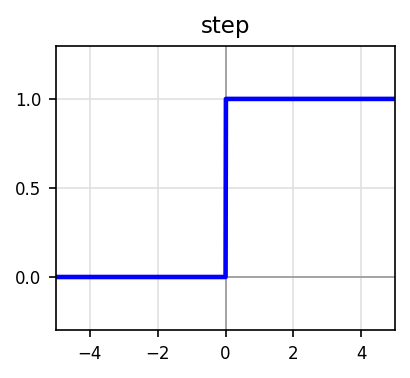

In [ ]:
# Type the import line: numpy as np

p = np.array([-2, 0, 3])          # test input

def step(x):
    return ___

print(step(p))                   # [0 0 1]

#### 7-(2) `elu`

- 각 원소에 대해 $x > 0$이면 $x$, 아니면 $e^{x} - 1$

이런 모양이 나와야 함:

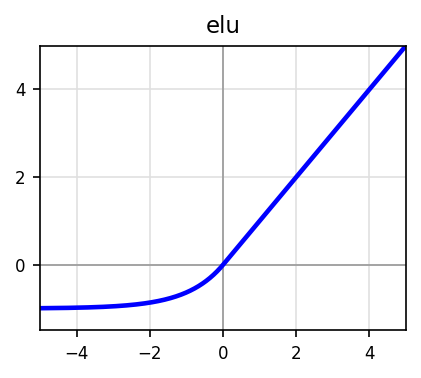

In [ ]:
def elu(x):
    return ___

print(np.round(elu(p), 3))       # [-0.865  0.     3.   ]

#### 7-(3) `softplus`

- 각 원소에 대해 $\log(1 + e^{x})$ (`np.log`)

이런 모양이 나와야 함:

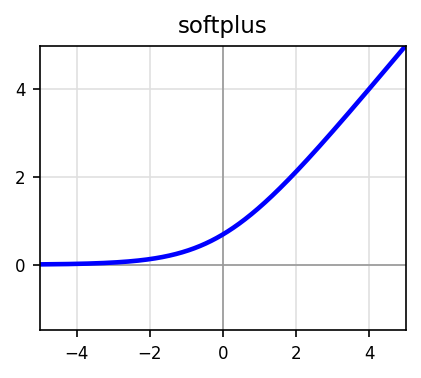

In [ ]:
def softplus(x):
    return ___

print(np.round(softplus(p), 3))  # [0.127 0.693 3.049]

#### 7-(4) `swish`

- 각 원소에 대해 $x \times \text{sigmoid}(x)$ (Problem 2의 `sigmoid` 이용)

이런 모양이 나와야 함:

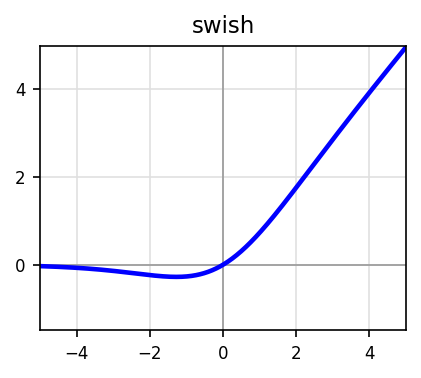

In [ ]:
def swish(x):
    return ___

print(np.round(swish(p), 3))     # [-0.238  0.     2.858]

#### 7-(5) `myAbs`

- 각 원소에 대해 $|x|$ (`np.abs`를 쓰지 말고 `np.where`로)

이런 모양이 나와야 함:

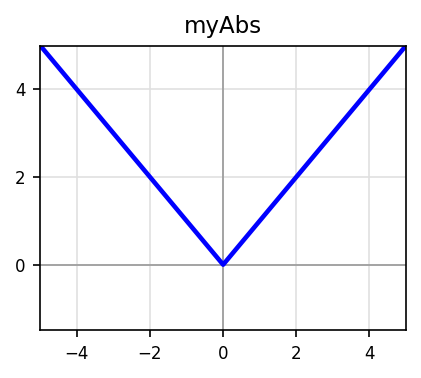

In [ ]:
def myAbs(x):
    return ___

print(myAbs(p))                  # [2 0 3]

#### 7-(6) 무기 목록

새 무기 다섯 개와 `sigmoid`를 한꺼번에 그려서 모양 확인 (실행만).

In [ ]:
drawCatalog({"step": step, "elu": elu, "softplus": softplus,
             "swish": swish, "myAbs": myAbs, "sigmoid": sigmoid})

#### 7-(7) 보너스 레벨 6~8

새 무기로 보너스 레벨 6~8을 깨기: `f6`, `f7`, `f8` (처음에는 `return 0 * x`)
- Level 6 Valley: V자로 내려갔다 올라가기
- Level 7 Elevator: 수직으로 점프
- Level 8 Ramp: 평평하다가 올라가기

#### Level 6: Valley

**Hint:** V자 a \* myAbs(x - c)

In [ ]:
def f6(x):
    return 0 * x                     # change this!

result = shoot(f6, LEVELS[6])
print(result)                        # goal: HIT
drawShot(f6, LEVELS[6], result)

#### Level 7: Elevator

**Hint:** 수직 점프 a \* step(x - c)

In [ ]:
def f7(x):
    return 0 * x                     # change this!

result = shoot(f7, LEVELS[7])
print(result)                        # goal: HIT
drawShot(f7, LEVELS[7], result)

#### Level 8: Ramp

**Hint:** 평평하다가 오르막 softplus(x - c) 또는 relu(x - c)

In [ ]:
def f8(x):
    return 0 * x                     # change this!

result = shoot(f8, LEVELS[8])
print(result)                        # goal: HIT
drawShot(f8, LEVELS[8], result)

### Bonus: AI가 대신 쏘기 (실행만)

지금까지 여러분은 `3 * relu(x - 4) + 6 * sigmoid(x - 15)`처럼 **무기를 크기만큼 곱하고, 옮기고, 더해서** 총알을 만들었습니다. 이 모양이 바로 **신경망(neural network)** 입니다.

- `network(p, x)`: 뉴런 N개의 합. 뉴런 하나는 `a * ACT(w * (x - c))`. 숫자 `p`(각 뉴런의 높이 `a`, 가파른 정도 `w`, 위치 `c`)가 총알 모양을 정함
- `loss(p, level)`: 총알이 얼마나 나쁜지 $\mathcal{L}$ (과녁에서 빗나간 정도 + 장애물에 파고든 정도 + 화면 밖으로 나간 정도). 0이면 완벽
- `train(level)`: 숫자 하나하나를 아주 조금 바꿔 보고, loss가 줄어드는 쪽으로 모든 숫자를 조금씩 옮기기를 800번 반복 (**경사하강법**). 여러분이 손으로 하던 "고치고 다시 쏘기"를 컴퓨터가 대신 함

위에서부터 순서대로 실행. 4번 그림: 학습할수록 궤적이 어떻게 고쳐지는지 (연한 색 = 처음, 진한 색 = 나중). 5번: 맵 12개에서 각각 학습시켜 테스트.

해 볼 것:
- 4번의 `level`을 `LEVELS[2]`, `randomLevel(7)`, `TWO_HOLES` 등으로 바꿔 보기
- `LEVELS[4]` (The Wall): AI도 막힘. 왜 그럴까? (조금씩 바꿔 봐도 나아지지 않는 곳에 갇힘: local minimum)
- `level = TWO_HOLES` (구멍이 위아래 2개인 맵): `SEED = 1`이면 위 구멍, `SEED = 2`면 아래 구멍. 같은 방법인데 처음 랜덤 숫자(시작점)만 달라도 다른 길로 감
- `ACT = relu`로 바꾸면? 12개 중 6개만 명중. 그런데 `LR = 0.0005`로 낮추면? (relu는 끝없이 커지는 직선이라 한 번에 조금씩 고쳐야 함)
- `ACT = tanh`도 해 보기

In [ ]:
import numpy as np

N = 6             # 뉴런 개수
ACT = sigmoid     # 뉴런에 쓸 무기 (relu, tanh 로 바꿔 보기)
LR = 0.005        # 학습률: 한 번에 얼마나 크게 고칠까
SEED = 1          # 처음 랜덤 숫자를 정하는 seed (바꿔 보기)

#### 1. 신경망: 뉴런 N개의 합

뉴런 하나는 여러분이 쏘던 모양 그대로: $a \cdot \mathrm{ACT}\big(w\,(x - c)\big)$

- $a$: 높이 (얼마나 크게), $w$: 가파른 정도, $c$: 위치 ($x = c$ 근처에서 바뀜)
- 신경망 = 뉴런 $N$개를 더한 것:

$$f(x) = \sum_{i=1}^{N} a_i \cdot \mathrm{ACT}\big(w_i\,(x - c_i)\big) = a_1\,\mathrm{ACT}\big(w_1(x-c_1)\big) + \cdots + a_N\,\mathrm{ACT}\big(w_N(x-c_N)\big)$$

- 학습으로 고칠 숫자: $p = (a_1, \dots, a_N,\ w_1, \dots, w_N,\ c_1, \dots, c_N)$. $N = 6$이면 **18개**
- 처음 숫자는 **랜덤** (`SEED`로 정함): $a$는 0 근처, $w$는 0.5~1.5, $c$는 0~18
- 예: $N = 1$, $a_1 = 7$, $w_1 = 1.5$, $c_1 = 10$이면 Level 5 정답 `7 * sigmoid(1.5 * (x - 10))`과 같음

In [ ]:
# 뉴런 하나 = a * ACT(w * (x - c))   <- 여러분이 쏘던 모양과 같음
#   a: 높이(크기),  w: 가파른 정도,  c: 위치(x = c 근처에서 바뀜)
# p: 숫자 3N개를 한 줄로 [a_1 .. a_N, w_1 .. w_N, c_1 .. c_N]
def network(p, x):
    a = p[0:N]                  # 높이 N개
    w = p[N:2 * N]              # 가파른 정도 N개
    c = p[2 * N:3 * N]          # 위치 N개
    y = 0 * x
    for i in range(N):
        y = y + a[i] * ACT(w[i] * (x - c[i]))   # 뉴런 i를 더함
    return y

#### 2. loss: 총알이 얼마나 나쁜가 (0이면 완벽)

총알이 얼마나 나쁜지를 숫자 하나로. $f$는 원점에서 출발하게 옮긴 총알, 과녁 $(x_{\text{target}}, y_{\text{target}})$, 장애물 중심 $(c_x, c_y)$와 반지름 $r$:

$$\text{miss} = \big(f(x_{\text{target}}) - y_{\text{target}}\big)^2$$

$$\text{wall} = \sum_{\text{장애물}} \Big[\max\big(0,\ {\color{green}1.1}\,r - \min_k d_k\big)\Big]^2, \qquad d_k = \sqrt{(x_k - c_x)^2 + (f(x_k) - c_y)^2}$$

- $x_k$: 장애물마다 그 장애물이 걸친 구간 $c_x - r \sim c_x + r$을 점 10개로 나눈 것. 총알 위의 점 $= \big(x_k, f(x_k)\big)$

$$\text{out} = \operatorname{mean} \Big[\big(\max(0,\ |f(x)| - 9.5)\big)^2\Big] \quad (0 \le x \le x_{\text{target}}\text{에서 점 201개})$$

$$\boxed{\mathcal{L} = \text{miss} + {\color{green}300} \cdot \text{wall} + {\color{green}10} \cdot \text{out}}$$

- miss: 과녁 위치에서 총알 높이와 과녁 높이의 차이를 제곱
- $d_k$: 총알의 점 $k$에서 장애물 중심까지 거리. 그중 **가장 가까운 점**($\min_k d_k$)이 반지름의 1.1배보다 가까우면 (여유 안쪽으로 들어오면) 들어온 만큼 벌점, 멀면 0 ($\max(0, \cdot)$: 밖에 있으면 벌점 없음)
- 막혀도 총알 그래프를 과녁 $x$까지 **끝까지 그려서** 잼 (BLOCKED/MISS 글자는 안 씀)
- 제곱이라 깊이 들어갈수록 벌점이 빠르게 커짐. 장애물은 300배로 아주 크게 벌점
- 초록색 숫자 ($\color{green}300$, $\color{green}1.1$, $\color{green}10$): **실험으로 찾은 값** (하이퍼파라미터)
- 과녁 정중앙에 맞고 장애물과 화면 밖을 다 피하면 $\mathcal{L} = 0$

In [ ]:
def loss(p, level):
    tx, ty, tr = level["target"]
    x = np.linspace(0, tx, 201)
    y = startAtOrigin(network(p, x))            # 원점에서 출발 (Problem 4)

    miss = (y[-1] - ty) ** 2                    # (1) 과녁 높이와 차이의 제곱

    wall = 0                                    # (2) 장애물에 파고든 정도
    for cx, cy, r in level["walls"]:
        xk = np.linspace(cx - r, cx + r, 10)    # 장애물이 걸친 구간에 점 10개
        fk = network(p, xk) - network(p, np.array([0.0]))[0]   # 그 점에서 총알 높이
        d = np.sqrt((xk - cx) ** 2 + (fk - cy) ** 2)   # 장애물 중심까지 거리
        dig = max(0, 1.1 * r - np.min(d))       # 가장 가까운 점이 반지름의 1.1배(여유)보다 안쪽으로 들어온 만큼
        wall = wall + dig ** 2

    out = np.mean(np.maximum(0, np.abs(y) - 9.5) ** 2)   # (3) 화면 밖으로 나간 정도

    return miss + 300 * wall + 10 * out         # 300, 10, 1.1: 실험으로 찾은 값

#### 3. 학습: loss가 줄어드는 쪽으로 숫자를 조금씩 고치기

숫자 $p_j$ 하나하나에 대해 (18개 모두):

**(1) 기울기 구하기**: $p_j$만 아주 조금 ($h = 0.0001$) 올려 보고 $\mathcal{L}$이 얼마나 변하는지

$$\frac{\Delta \mathcal{L}}{\Delta p_j} = \frac{\mathcal{L}(p_1, \dots, p_j + h, \dots) - \mathcal{L}(p_1, \dots, p_j, \dots)}{h}$$

- $\frac{\Delta \mathcal{L}}{\Delta p_j} > 0$: $p_j$를 올리면 $\mathcal{L}$이 커짐 $\rightarrow$ 내려야 함
- $\frac{\Delta \mathcal{L}}{\Delta p_j} < 0$: $p_j$를 올리면 $\mathcal{L}$이 작아짐 $\rightarrow$ 올려야 함
- $h$가 크면 (0.1) 넓은 구간의 평균이라 부정확, 너무 작으면 ($10^{-15}$) 컴퓨터 반올림 오차로 부정확

**(2) 숫자 고치기**: 기울기 반대 방향으로 조금 (학습률 $\text{LR} = 0.005$)

$$p_j \leftarrow p_j - \text{LR} \cdot \operatorname{clip}\Big(\frac{\Delta \mathcal{L}}{\Delta p_j},\ -20,\ 20\Big)$$

- clip: 기울기가 너무 크면 $-20 \sim 20$으로 잘라서 한 번에 너무 멀리 가지 않게
- 예: 기울기가 4이면 $p_j$가 $0.005 \times 4 = 0.02$만큼 줄어듦
- 이것을 **800번** 반복 = **경사하강법** (gradient descent). 매번 $\mathcal{L}$이 조금씩 줄어듦

In [ ]:
def train(level, steps=800, lr=LR, seed=SEED):
    rng = np.random.default_rng(seed)
    # 처음 숫자는 랜덤
    a = rng.normal(0, 0.3, N)          # 높이: 0 근처 작은 값 -> 처음엔 거의 평평
    w = rng.uniform(0.5, 1.5, N)       # 가파른 정도: 0.5 ~ 1.5
    c = rng.uniform(0, 18, N)          # 위치: 0 ~ 18
    p = np.concatenate([a, w, c])      # 숫자 3N개를 한 줄로

    snapshots = []                     # 중간 결과 (그림용)
    losses = []                        # loss 기록 (그래프용)
    for step in range(steps + 1):
        if step in [0, 5, 10, 20, 40, 80, 160, 400, steps]:
            snapshots.append((step, p.copy()))
        L = loss(p, level)
        losses.append(L)

        # 기울기(gradient): 숫자 j를 아주 조금(h) 올리면 loss가 얼마나 변하나?
        h = 0.0001
        grad = np.zeros(len(p))
        for j in range(len(p)):
            q = p.copy()
            q[j] = q[j] + h
            grad[j] = (loss(q, level) - L) / h

        # 기울기 반대 방향 = loss가 줄어드는 쪽으로 조금(lr) 이동
        # (한 번에 너무 크게 움직이지 않도록 -20 ~ 20으로 자름)
        p = p - lr * np.clip(grad, -20, 20)
    return p, snapshots, losses

#### 4. 한 맵에서 학습 과정 보기

`train(level)`로 학습하고 그림 두 개:

- 왼쪽: step 0, 5, 10, 20, 40, 80, 160, 400, 800일 때의 궤적을 한 맵에 겹쳐 그림 (연한 색 = 처음, 진한 색 = 나중). 처음엔 거의 평평 $\rightarrow$ 장애물 사이로 휘기 시작 $\rightarrow$ 과녁에 붙음
- 오른쪽: step마다의 $\mathcal{L}$ (세로축이 log 눈금: 한 칸 = 100배). 점은 왼쪽 궤적을 그린 시점
- 학습이 끝난 숫자 $p$로 `aiShot(x)` $= f(x)$를 만들어 Problem 4의 `shoot`으로 쏨

In [ ]:
level = LEVELS[5]           # 다른 맵으로 바꿔 보기: LEVELS[2], TWO_HOLES
p, snapshots, losses = train(level)
showTraining(level, network, snapshots, losses)   # 학습할수록 궤적이 어떻게 바뀌나

def aiShot(x):
    return network(p, x)

result = shoot(aiShot, level)
print(result)
drawShot(aiShot, level, result)

#### 5. 여러 맵에서 테스트

맵 12개 (레벨 1~8, 랜덤 맵 4개)마다 **처음부터 새로** 학습하고 쏨. 같은 방법이 여러 맵에서도 통하는지 확인.

- 맵마다 결과 출력, 마지막에 HIT 개수
- 그림: 맵마다 학습된 궤적 (제목이 초록 = HIT, 빨강 = 실패)

In [ ]:
tests = []                          # 테스트할 맵 12개
for k in range(1, 9):
    tests.append(LEVELS[k])         # 레벨 1 ~ 8
for seed in [1, 2, 3, 7]:
    tests.append(randomLevel(seed)) # 랜덤 맵 4개

shots = []                  # (맵, 학습된 숫자 p, 결과)
hits = 0
for level in tests:
    p, snapshots, losses = train(level)          # 맵마다 새로 학습
    def aiShot(x):
        return network(p, x)
    result = shoot(aiShot, level)
    print(level["name"], ":", result)
    if result == "HIT":
        hits = hits + 1
    shots.append((level, p, result))
print("HIT:", hits, "/", len(tests))
showResults(shots, network)